1. Import Libraries

In [118]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


2. Load the Dataset

In [119]:
df = pd.read_csv(r"C:\Users\HARSH\OneDrive\Desktop\churn_rate_model\WA_Fn-UseC_-Telco-Customer-Churn.csv")

In [120]:
df.shape

(7043, 21)

In [121]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [122]:
pd.set_option("display.max_columns",None)

In [123]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [125]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='str')

In [126]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [127]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [128]:
df.duplicated().sum()

np.int64(0)

In [129]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

no missing values in any column

dropping customer id column 

In [130]:
df = df.drop(columns=["customerID"])

In [132]:
df.columns

Index(['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure',
       'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity',
       'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV',
       'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod',
       'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='str')

In [133]:
excluding_list = ["tenure","MonthlyCharges", "TotalCharges"]
for i in df.columns:
    if i not in excluding_list:
        print (f"{i} -> {df[i].unique().tolist()}")

gender -> ['Female', 'Male']
SeniorCitizen -> [0, 1]
Partner -> ['Yes', 'No']
Dependents -> ['No', 'Yes']
PhoneService -> ['No', 'Yes']
MultipleLines -> ['No phone service', 'No', 'Yes']
InternetService -> ['DSL', 'Fiber optic', 'No']
OnlineSecurity -> ['No', 'Yes', 'No internet service']
OnlineBackup -> ['Yes', 'No', 'No internet service']
DeviceProtection -> ['No', 'Yes', 'No internet service']
TechSupport -> ['No', 'Yes', 'No internet service']
StreamingTV -> ['No', 'Yes', 'No internet service']
StreamingMovies -> ['No', 'Yes', 'No internet service']
Contract -> ['Month-to-month', 'One year', 'Two year']
PaperlessBilling -> ['Yes', 'No']
PaymentMethod -> ['Electronic check', 'Mailed check', 'Bank transfer (automatic)', 'Credit card (automatic)']
Churn -> ['No', 'Yes']


In [134]:
df["TotalCharges"]=df["TotalCharges"].replace({" ":"0.0"})
df["TotalCharges"]=df["TotalCharges"].astype(float)

In [135]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692,2279.734304
std,0.368612,24.559481,30.090047,2266.794470
min,0.000000,0.000000,18.250000,0.000000
25%,0.000000,9.000000,35.500000,398.550000
50%,0.000000,29.000000,70.350000,1394.550000
75%,0.000000,55.000000,89.850000,3786.600000
max,1.000000,72.000000,118.750000,8684.800000


EDA

DISTRIBUTION OF TARGET

In [136]:
df["Churn"].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

imbalanced data

DISTRIBUTION OF NUMERICAL COLUMNS

In [137]:
def plot_histplot(df,column):
    plt.figure(figsize=(5,3))
    sns.histplot(df[column],kde=True)
    plt.title(f"{column} distribution")

    col_mean = df[column].mean()
    col_med = df[column].median()

    plt.axvline(col_mean,linestyle = "--",label = "mean_line")
    plt.axvline(col_med,linestyle = "-",label = "median_line")
    plt.legend()

    plt.show()

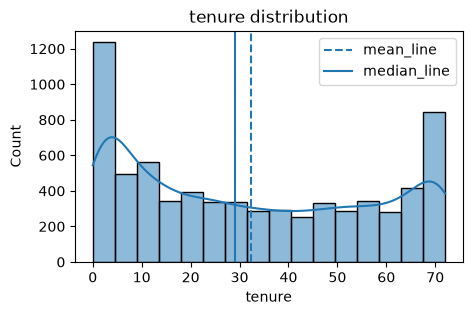

In [138]:
plot_histplot(df,"tenure")

In [139]:

print(f"tenure has a bi-modal curve with skewness value as{round(df["tenure"].skew(),2)} which shows very less skewness")

tenure has a bi-modal curve with skewness value as0.24 which shows very less skewness


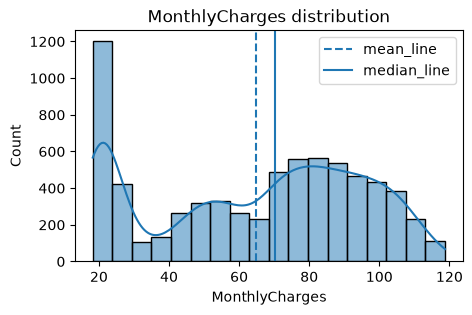

In [140]:
plot_histplot(df,"MonthlyCharges")

In [141]:
print(f"tenure has a multi-modal curve with skewness value as{round(df["MonthlyCharges"].skew(),2)} which shows a little left(negative) skewness")

tenure has a multi-modal curve with skewness value as-0.22 which shows a little left(negative) skewness


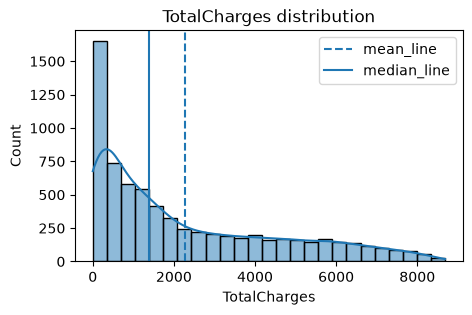

In [142]:
plot_histplot(df,"TotalCharges")

In [143]:
print(f"total charges has a right skew curve with skewness value as{round(df["TotalCharges"].skew(),2)}")

total charges has a right skew curve with skewness value as0.96


categorical_col v/s target

In [144]:
def plot_cat(df,col,ax):
    ct = pd.crosstab(df[col], df["Churn"], normalize="index") * 100

    ct.plot(kind="bar", stacked=True,ax=ax)

    for c in ax.containers:
        ax.bar_label(c, fmt="%.1f%%", label_type="center")

    ax.set_title(f"Churn % by {col}")
    ax.set_ylabel("Percentage")
    ax.tick_params(axis="x", rotation=0)
    

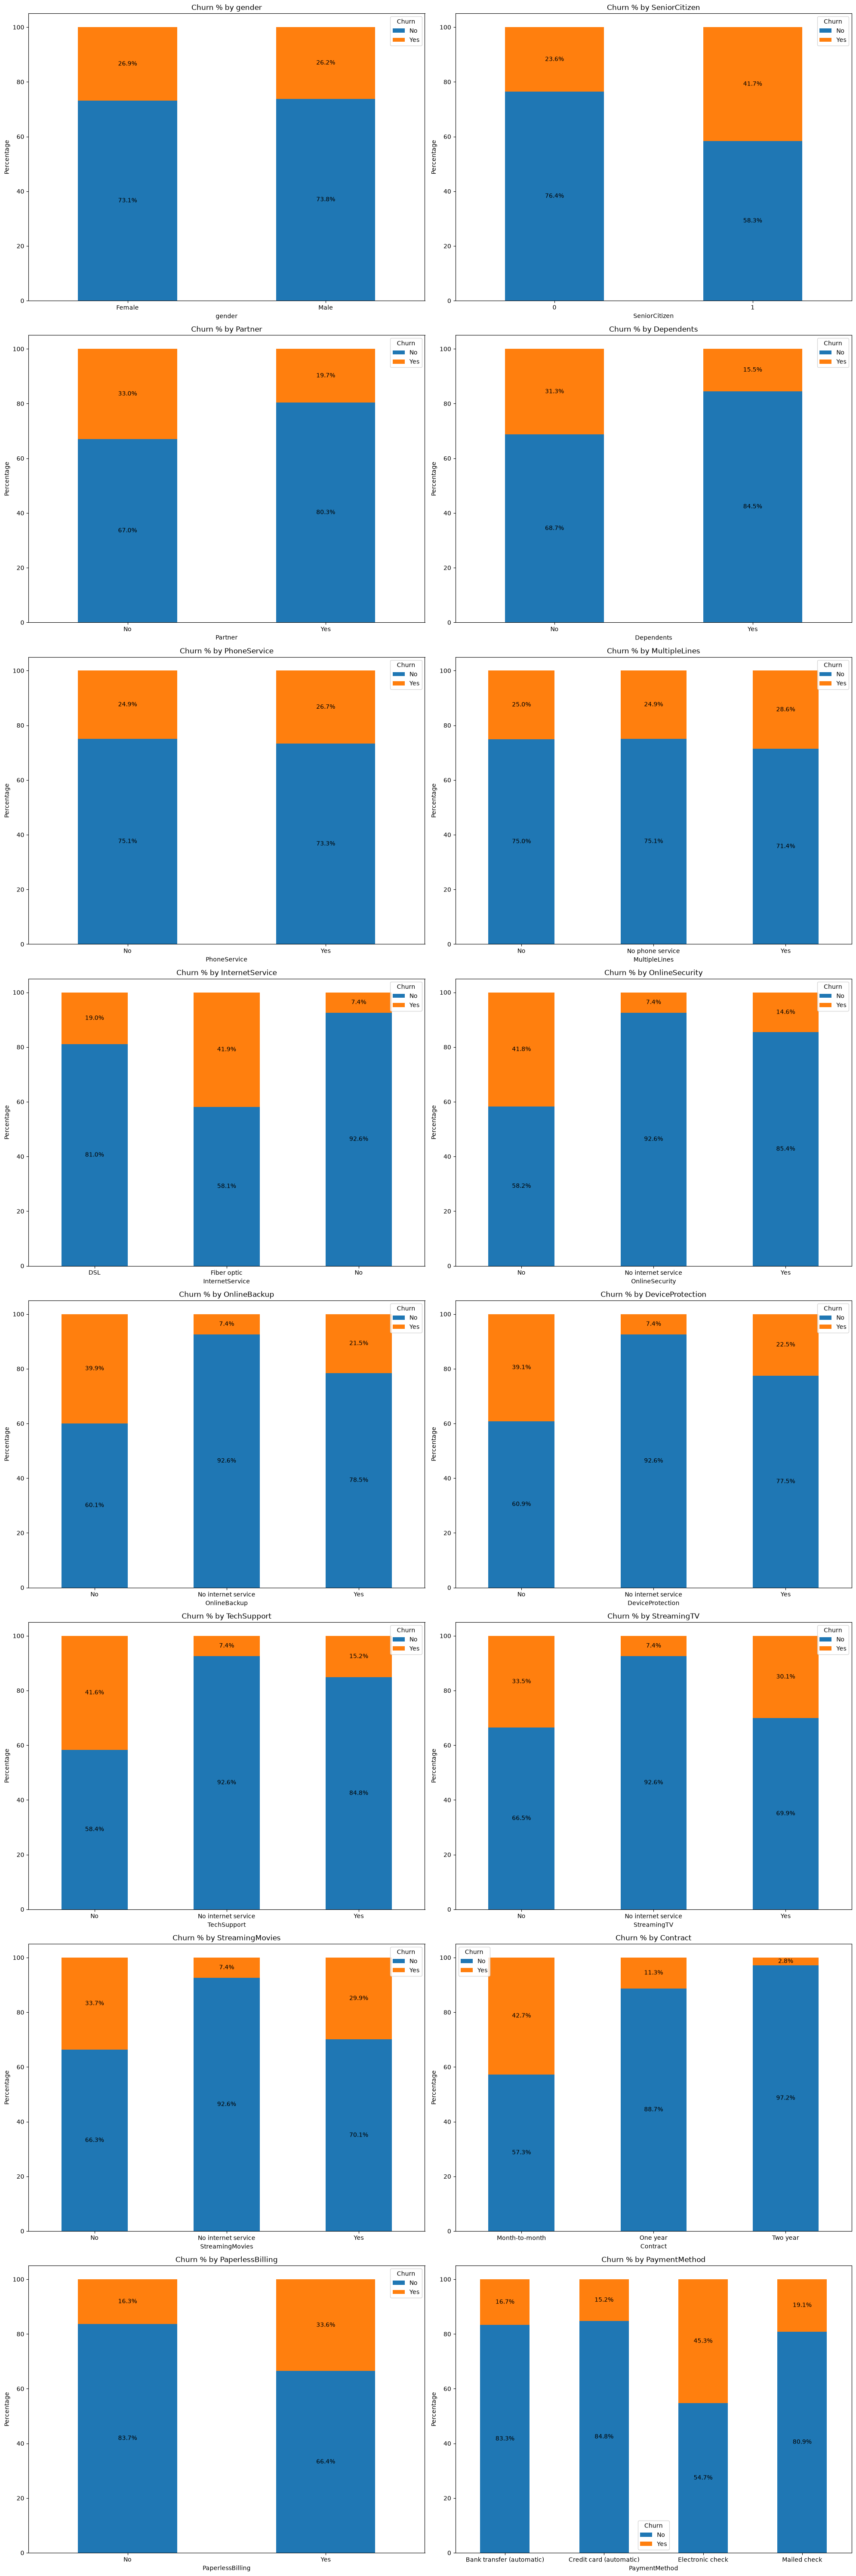

In [145]:
cols = [c for c in df.columns if c not in excluding_list + ["Churn"]]

fig, axes = plt.subplots(8, 2, figsize=(20, 60))

for ax, col in zip(axes.ravel(), cols):
    plot_cat(df, col, ax)

plt.tight_layout()
plt.show()

<Axes: ylabel='tenure'>

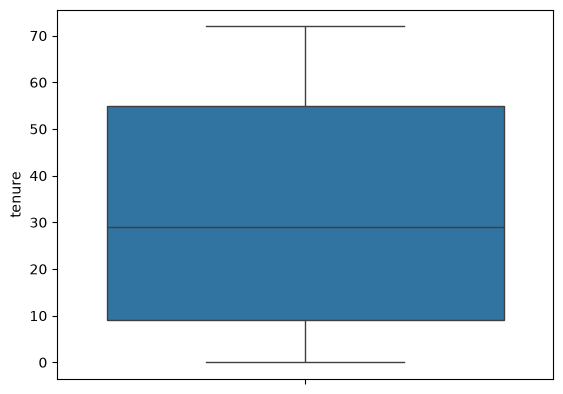

In [146]:
sns.boxplot(df,y="tenure")

<Axes: ylabel='MonthlyCharges'>

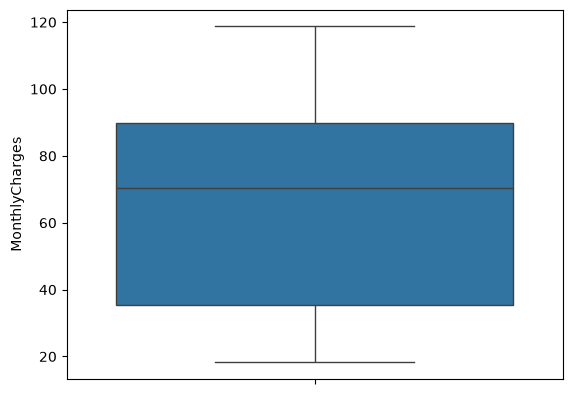

In [147]:
sns.boxplot(df,y="MonthlyCharges")

<Axes: ylabel='TotalCharges'>

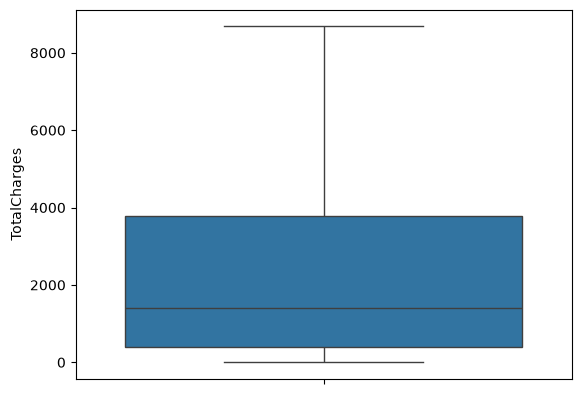

In [148]:
sns.boxplot(df,y="TotalCharges")

FEATURE ENGINEEERING


In [149]:
df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})

In [150]:
addons = ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
          'TechSupport', 'StreamingTV', 'StreamingMovies']

for c in addons:
    df[c] = df[c].replace('No internet service', 'No').map({'Yes': 1, 'No': 0})

In [151]:
df['MultipleLines'] = df['MultipleLines'].replace('No phone service', 'No').map({'Yes': 1, 'No': 0})

In [152]:
yes_no_cols = ['Partner', 'Dependents', 'PhoneService', 'PaperlessBilling']
for c in yes_no_cols:
    df[c] = df[c].map({'Yes': 1, 'No': 0})


df['gender'] = df['gender'].map({'Female': 0, 'Male': 1})

In [153]:
df.head(2)

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,0,0,1,0,1,0,0,DSL,0,1,0,0,0,0,Month-to-month,1,Electronic check,29.85,29.85,0
1,1,0,0,0,34,1,0,DSL,1,0,1,0,0,0,One year,0,Mailed check,56.95,1889.50,0


In [160]:

from sklearn.model_selection import train_test_split,cross_val_score

skewed_col = ['TotalCharges']
other_num_col = ['tenure','MonthlyCharges']

ordinal_col = ['Contract']
nominal_col = ['InternetService','PaymentMethod']

x = df.iloc[:, :-1]   
y = df.iloc[:, -1] 

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.30, random_state=42)


In [161]:

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler, OrdinalEncoder, OneHotEncoder
from sklearn.compose import ColumnTransformer
#1. Skewed features
skew_pipeline = Pipeline(steps=[
    ('log_transform', FunctionTransformer(np.log1p)),
    ('scale', StandardScaler())

])

#2. Numeric Features
plain_numeric_pipeline = Pipeline(steps=[
    ('scale',StandardScaler())
])

#3. Ordinal
ordinal_pipeline = Pipeline(steps=[
    ('encode', OrdinalEncoder(categories=[['Month-to-month', 'One year', 'Two year']]))
])

#4. Nominal Features
nominal_pipeline = Pipeline(steps=[
    ('encode', OneHotEncoder(handle_unknown="ignore"))
])


    # (konsi_pipeline, konsa_feature)
preprocessor = ColumnTransformer(transformers=[
    ("Skewed_Pipeline", skew_pipeline, skewed_col),
    ("Plain_Numeric",plain_numeric_pipeline, other_num_col ),
    ('Ordinal', ordinal_pipeline, ordinal_col),
    ('Normal', nominal_pipeline, nominal_col)
])



Applying a Baseline model

Logistic Regression

In [164]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, recall_score, precision_score

lr_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', LogisticRegression())
])

lr_pipeline.fit(x_train,y_train)
lr_preds = lr_pipeline.predict(x_test)


print('Precision:', round(precision_score(y_test, lr_preds), 3))
print('Recall   :', round(recall_score(y_test,lr_preds), 3))


print('CV Recall   :', cross_val_score(lr_pipeline, x_train, y_train, cv=5, scoring='recall').mean().round(3))
print('CV Precision:', cross_val_score(lr_pipeline, x_train, y_train, cv=5, scoring='precision').mean().round(3))

Precision: 0.688
Recall   : 0.495
CV Recall   : 0.475
CV Precision: 0.656
